In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neural_network import MLPClassifier

In [2]:
# "penguins" dataset in seaborn:
# Original Research Paper: 
# Gorman KB, Williams TD, Fraser WR (2014) Ecological Sexual Dimorphism 
# and Environmental Variability within a Community of Antarctic Penguins 
# (Genus Pygoscelis). PLoS ONE 9(3): e90081
# Environmental Data Initiative (EDI): The raw ecological datasets 
# (#219, #220, #221) containing extra variables such as blood isotope 
# ratios and egg clutch observations are hosted directly on the 
# Environmental Data Initiative (EDI) Data Portal under the 
# Palmer Station LTER project.   


# Load Palmer Penguins dataset and drop rows with missing values
df = sns.load_dataset('penguins').dropna()

# Describe the data
df.describe(include='all')


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,333,333,333.000000,333.000000,333.000000,333.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male
freq,146,163,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.992793,17.164865,200.966967,4207.057057,NaN
std,NaN,NaN,5.468668,1.969235,14.015765,805.215802,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.500000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.500000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.600000,18.700000,213.000000,4775.000000,NaN


In [3]:
# What are the different species of penguins?
print(df['species'].unique())

<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str


In [4]:
species_codes = {'Adelie': 1, 'Chinstrap': 2, 'Gentoo': 3}
df['species_code'] = df['species'].map(species_codes)

df[['species', 'species_code']].drop_duplicates().sort_values('species_code')

,species,species_code
0,Adelie,1
152,Chinstrap,2
220,Gentoo,3


In [5]:
# Describe the data
df.describe(include='all')

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species_code
count,333,333,333.000000,333.000000,333.000000,333.000000,333,333.000000
unique,3,3,NaN,NaN,NaN,NaN,2,NaN
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male,NaN
freq,146,163,NaN,NaN,NaN,NaN,168,NaN
mean,NaN,NaN,43.992793,17.164865,200.966967,4207.057057,NaN,1.918919
std,NaN,NaN,5.468668,1.969235,14.015765,805.215802,NaN,0.889718
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN,1.000000
25%,NaN,NaN,39.500000,15.600000,190.000000,3550.000000,NaN,1.000000
50%,NaN,NaN,44.500000,17.300000,197.000000,4050.000000,NaN,2.000000
75%,NaN,NaN,48.600000,18.700000,213.000000,4775.000000,NaN,3.000000


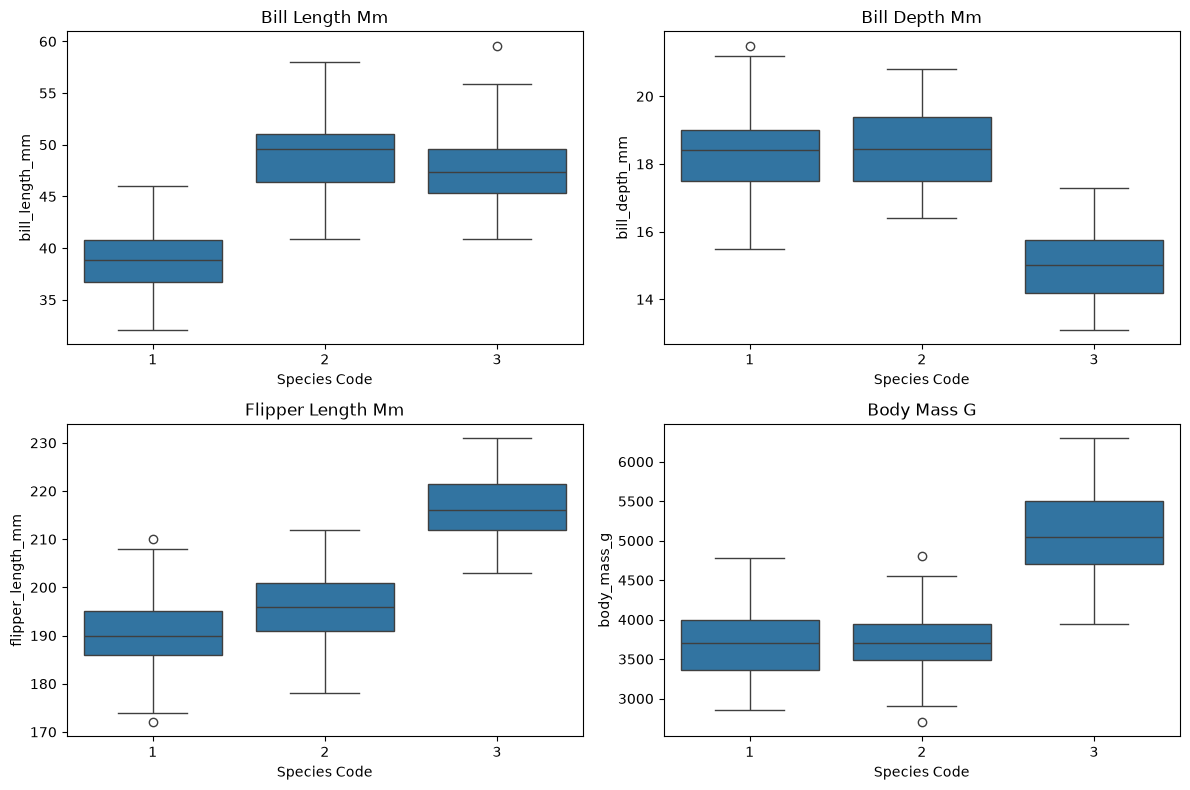

In [6]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df, x='species_code', y=feature, ax=ax)
    ax.set_title(feature.replace('_', ' ').title())
    ax.set_xlabel('Species Code')

plt.tight_layout()
plt.show()

In [7]:
# Encode categorical features (species, island, sex) and define targets
# Let's say we want to predict species from lots of other variables:
X = pd.get_dummies(df[['flipper_length_mm']], drop_first=True)
y = df['species_code']
print(X.shape)
print(y.shape)

(333, 1)
(333,)


In [8]:
# Split the penguin data in train and test data (80:20)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [9]:
# scale the training data
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
# now build the neural network using MLPClassifier
# MLPClassifier stands for Multi-layer Perceptron classifier

# https://analyticsindiamag.com/a-beginners-guide-to-scikit-learns-mlpclassifier/

# the following code will create a classifier with three layers of 10 nodes each
# max_iter refers to the number of epochs, one epoch is a combination of one cycle of 
# feed-forward and back propagation phase.
mlp = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=1000)

# now fit the classifer to the training data
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


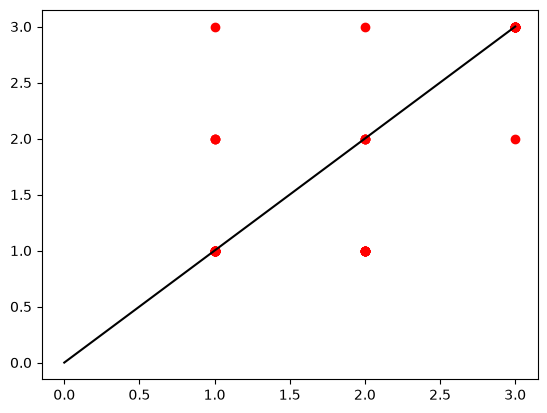

In [11]:
# try making some predictions using your classifier
predictions = mlp.predict(X_test)

plt.plot(y_test, predictions, 'ro')
plt.plot([0, 3], [0, 3],'k')

In [16]:
accuracy = metrics.accuracy_score(y_test, predictions)
f1 = metrics.f1_score(y_test, predictions, average='macro')

print(f"Accuracy: {accuracy:.3f}")
print(f"Macro F1 score: {f1:.3f}")

Accuracy: 0.373
Macro F1 score: 0.296


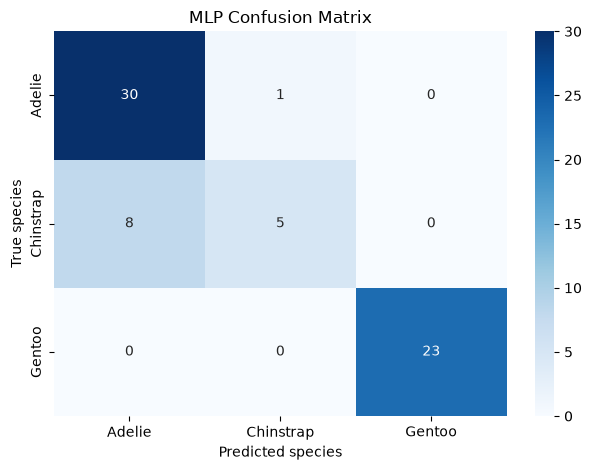

In [17]:
# X_test is raw data; scale it using the existing scaler before prediction
mlp_predictions = mlp.predict(scaler.transform(X_test))

cm = confusion_matrix(y_test, mlp_predictions, labels=[1, 2, 3])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Adelie', 'Chinstrap', 'Gentoo'],
    yticklabels=['Adelie', 'Chinstrap', 'Gentoo']
)
plt.xlabel('Predicted species')
plt.ylabel('True species')
plt.title('MLP Confusion Matrix')
plt.tight_layout()
plt.show()

In [18]:
# and now look at the accuracy of your predictions
print(confusion_matrix(y_test, mlp_predictions)) # Confusion Matrix

# We will use the confusion matrix to determine the accuracy which is measured as the total 
# number of correct predictions divided by the total number of predictions.

[[30  1  0]
 [ 8  5  0]
 [ 0  0 23]]


In [13]:
# Train/Test Split & Model Training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [14]:
# Jessie's "quickstats" function, originally written in matlab and translated here.
def quickstats(var1, var2):
    """
    Run basic statistics comparing predicted (var1) vs observed (var2) data.
    """
    var1 = np.asarray(var1).flatten()
    var2 = np.asarray(var2).flatten()
    
    mask = ~np.isnan(var1) & ~np.isnan(var2)
    v1 = var1[mask]
    v2 = var2[mask]
    
    if len(v1) == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    bias = np.mean(v1) - np.mean(v2)
    mean_ratio = np.mean(v1) / np.mean(v2)
    mae = np.mean(np.abs(v1 - v2))
    rmse = np.sqrt(np.mean((v1 - v2) ** 2))
    mean_apd = np.mean(np.abs((v1 - v2) / v2))
    
    r_matrix = np.corrcoef(v1, v2)
    r = r_matrix[0, 1] if r_matrix.shape == (2, 2) else np.nan
    
    return bias, mean_ratio, mae, rmse, mean_apd, r

In [15]:
# Evaluate Model Performance
bias, mean_ratio, mae, rmse, mean_apd, r = quickstats(y_pred, y_test)

print("--- Model Evaluation Metrics ---")
print(f"Bias:                          {bias:.2f} g")
print(f"Mean Ratio (Pred/Obs):         {mean_ratio:.4f}")
print(f"MAE:                           {mae:.2f} g")
print(f"RMSE:                          {rmse:.2f} g")
print(f"Mean APD (Absolute % Diff):    {mean_apd * 100:.2f}%")
print(f"Correlation Coefficient (R):    {r:.4f}")

--- Model Evaluation Metrics ---
Bias:                          0.02 g
Mean Ratio (Pred/Obs):         1.0098
MAE:                           0.26 g
RMSE:                          0.35 g
Mean APD (Absolute % Diff):    19.79%
Correlation Coefficient (R):    0.9211
